In [1]:
import os
import glob
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import pandas as pd
import matplotlib.patheffects as PathEffects
import arviz as az
from Functions_PyMC_MHWdetection import *

az.style.use("arviz-darkgrid")

plt.rcParams.update(
    {
        "figure.figsize": (14, 4),
        "figure.dpi": 144,
        "figure.constrained_layout.use": True,
        "axes.grid": True,
        "grid.linewidth": 0.5,
        "grid.linestyle": "--",
        "axes.spines.top": False,
        "axes.spines.bottom": False,
        "axes.spines.left": False,
        "axes.spines.right": False,
    }
)



def get_hemisphere(lat: float) -> str:
    """
    Return hemisphere based on latitude.
    
    Parameters
    ----------
    lat : float
        Latitude in degrees.
    
    Returns
    -------
    str
        "Northern Hemisphere" or "Southern Hemisphere"
    """
    if lat >= 0:
        return "Northern Hemisphere"
    else:
        return "Southern Hemisphere"



In [7]:
# --- Step 1: find all netCDF files in the current folder
current_folder = os.getcwd()
nc_files = glob.glob(f"{current_folder}\data\*.nc")   # or "*.nc4" depending on your files
labels = ['Japan','North West Shelf', 'South Western Australia',  'UK', 'WATR10 Mooring 50m',]

nc_files

['C:\\Users\\24048369\\OneDrive - The University of Western Australia\\Paper2_Github\\pymc_MHWdetection\\data\\1-Japan.nc',
 'C:\\Users\\24048369\\OneDrive - The University of Western Australia\\Paper2_Github\\pymc_MHWdetection\\data\\2-NorthWestShelf.nc',
 'C:\\Users\\24048369\\OneDrive - The University of Western Australia\\Paper2_Github\\pymc_MHWdetection\\data\\3-SouthWA.nc',
 'C:\\Users\\24048369\\OneDrive - The University of Western Australia\\Paper2_Github\\pymc_MHWdetection\\data\\4-UK.nc',
 'C:\\Users\\24048369\\OneDrive - The University of Western Australia\\Paper2_Github\\pymc_MHWdetection\\data\\5-SouthWA_WATR_100m.nc']

In [4]:


locations = []
timeseries = []

for f in range(len(nc_files)):
    ds = xr.open_dataset(nc_files[f])
    if f == 4:
        ds = ds.rename({
                "TIME": "time",
                "LONGITUDE": "longitude",
                "LATITUDE": "latitude",
                "TEMP": "temperature",
                "DEPTH": "depth",
                
            })
        ds = ds.resample(time="1D").mean(skipna=True)
        ds = ds.interpolate_na( dim="time", method="linear", limit=2 )
        ds = ds.interpolate_na(dim="depth", method="linear", limit=1 )
        ds = ds.sel(depth  = 50 )

    else:
        ds = ds.sel(time = slice(pd.to_datetime('1994-01-01'),pd.to_datetime('2025-01-01')))
    # Get lat/lon
    if "lat" in ds:
        lat_values = ds["lat"].values
    else:
        lat_values = ds["latitude"].values
    if "lon" in ds:
        lon_values = ds["lon"].values
    else:
        lon_values = ds["longitude"].values
    print(f'\n{f}')
    print(str(nc_files[f])[102:])
    print(f'Lat: {lat_values.mean(),lat_values.mean()}')
    print(f'Lon: {lon_values.mean(),lon_values.mean()}')
    
    lat = float(lat_values.mean())
    lon = float(lon_values.mean())

    print(get_hemisphere(lat))
    # Store location
    locations.append((lon, lat, str(nc_files[f])[102:]))

    # Try to extract SST or temperature variable
    if "sst" in ds:
        ts = ds["sst"].mean(dim=[d for d in ds["sst"].dims if d != "time"]).values
        time = ds["time"].values
    elif "temperature" in ds:
        if f != 4:
            ts = ds["temperature"].mean(dim=[d for d in ds["temperature"].dims if d != "time"]).values
        else: 
            ts = ds["temperature"].mean(dim=[d for d in ds["temperature"].dims if d != "time"]).values
            ts = ts + 273.15
        time = ds["time"].values
    elif "analysed_sst" in ds:
        ts = ds["analysed_sst"].mean(dim=[d for d in ds["analysed_sst"].dims if d != "time"]).values
        time = ds["time"].values
    else:
        raise ValueError(f"No SST/temperature variable found in {f}")

    timeseries.append((time, ts))
    ds.close()


0
1-Japan.nc
Lat: (np.float32(31.50001), np.float32(31.50001))
Lon: (np.float32(126.500015), np.float32(126.500015))
Northern Hemisphere

1
2-NorthWestShelf.nc
Lat: (np.float32(-18.499992), np.float32(-18.499992))
Lon: (np.float32(118.500015), np.float32(118.500015))
Southern Hemisphere

2
3-SouthWA.nc
Lat: (np.float32(-31.949995), np.float32(-31.949995))
Lon: (np.float32(115.4), np.float32(115.4))
Southern Hemisphere

3
4-UK.nc
Lat: (np.float32(52.500008), np.float32(52.500008))
Lon: (np.float32(-11.5), np.float32(-11.5))
Northern Hemisphere

4
5-SouthWA_WATR_100m.nc
Lat: (np.float64(-31.645758156363645), np.float64(-31.645758156363645))
Lon: (np.float64(115.20024414301963), np.float64(115.20024414301963))
Southern Hemisphere


C:\Users\24048369\AppData\Local\anaconda3\envs\pymc_env_new\lib\site-packages\scipy\stats\_axis_nan_policy.py:586: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 10958.
  res = hypotest_fun_out(*samples, **kwds)
C:\Users\24048369\AppData\Local\anaconda3\envs\pymc_env_new\lib\site-packages\scipy\stats\_axis_nan_policy.py:586: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 10958.
  res = hypotest_fun_out(*samples, **kwds)
C:\Users\24048369\AppData\Local\anaconda3\envs\pymc_env_new\lib\site-packages\scipy\stats\_axis_nan_policy.py:586: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 10958.
  res = hypotest_fun_out(*samples, **kwds)
C:\Users\24048369\AppData\Local\anaconda3\envs\pymc_env_new\lib\site-packages\scipy\stats\_axis_nan_policy.py:586: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current

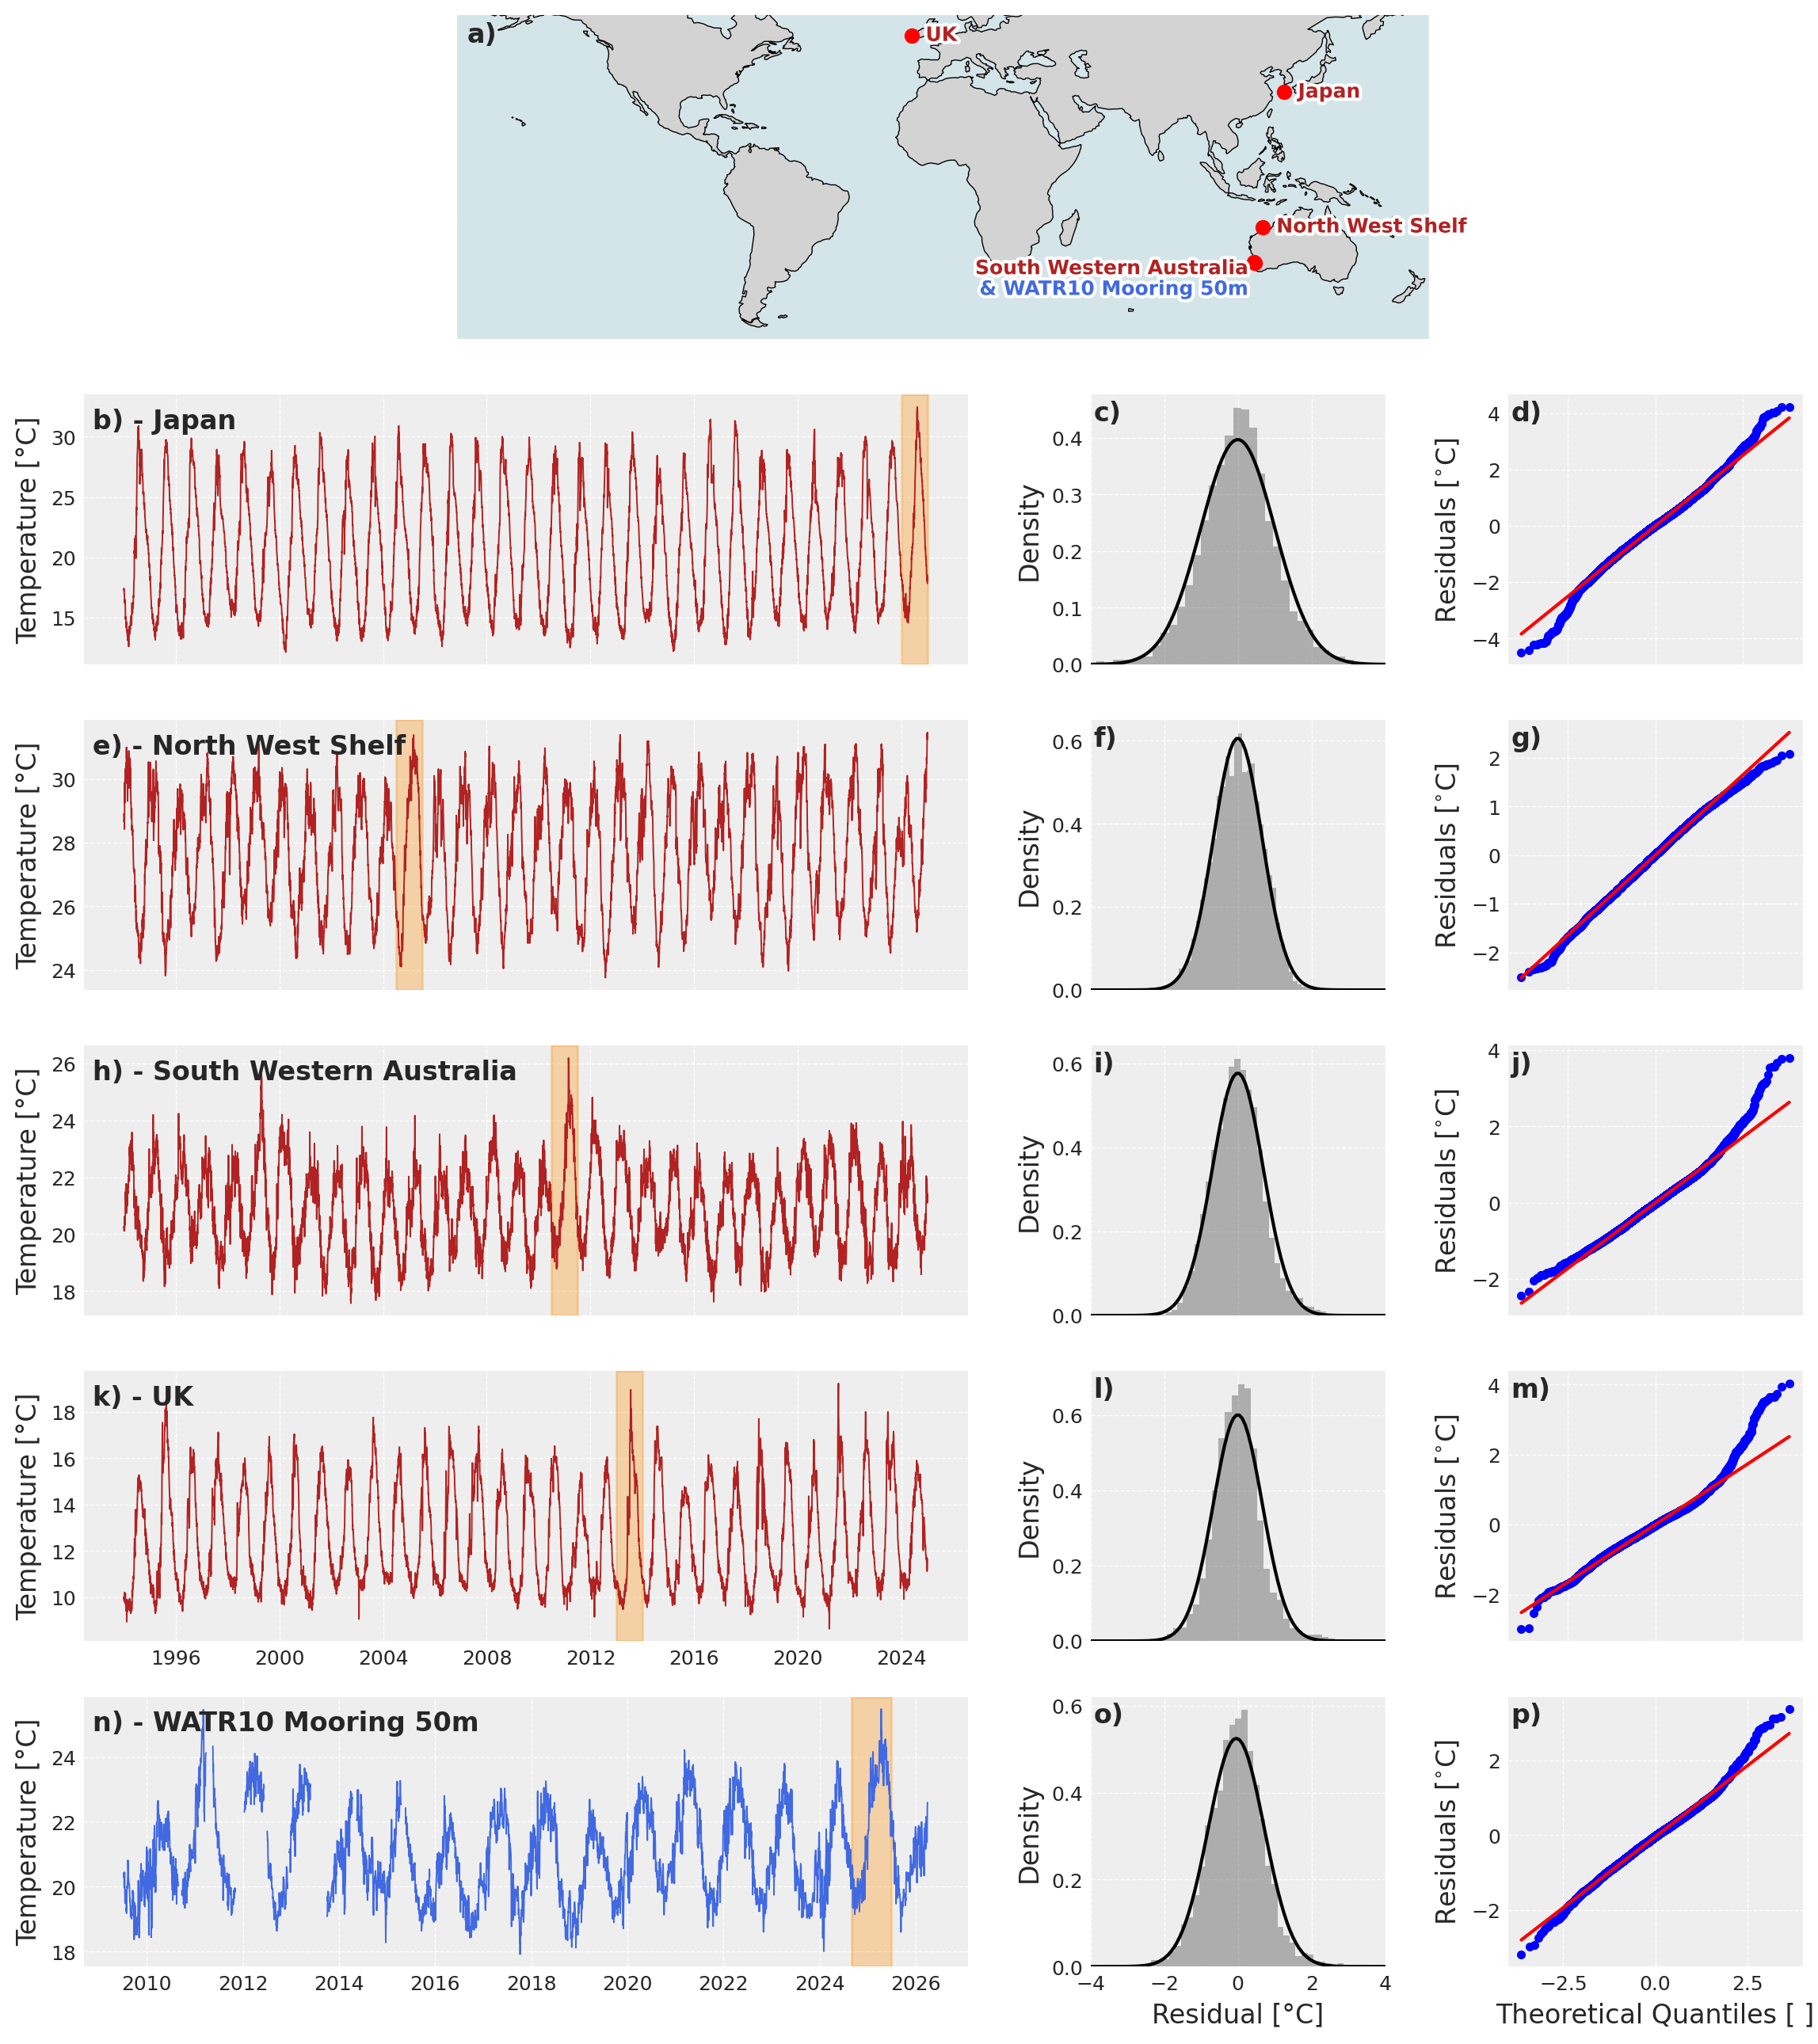

In [22]:
import matplotlib.gridspec as gridspec
from scipy import stats
import matplotlib.patheffects as PathEffects

# Standardizing font sizes for a "Nature" style
TITLE_FONT = 12
LABEL_FONT = 12
TICK_FONT = 9

fig = plt.figure(figsize=(14, 16), dpi=200)

gs = gridspec.GridSpec(
    nrows=6,
    ncols=3,
    figure=fig,
    width_ratios=[3, 1, 1],         
    height_ratios=[1.2, 1, 1, 1, 1,1], 
    hspace=0.20,
    wspace=0.25
)

# --- Map (top) ---
ax_map = fig.add_subplot(gs[0, :], projection=ccrs.PlateCarree())
ax_map.set_global()
ax_map.coastlines(linewidth=0.5)
ax_map.add_feature(cfeature.LAND, facecolor="lightgray")
ax_map.add_feature(cfeature.OCEAN, facecolor="lightblue", alpha=0.4)
ax_map.set_ylim(-60, 60)

# --- Subplot Lists ---
axes_ts = [fig.add_subplot(gs[i, 0]) for i in range(1, 6)]
axes_his = [fig.add_subplot(gs[i, 1]) for i in range(1, 6)]
axes_qq = [fig.add_subplot(gs[i, 2]) for i in range(1, 6)]

panel_labels = ['a)', 'b)', 'e)', 'h)', 'k)','n)']
panel_labels2 =      ['c)', 'f)', 'i)', 'l)','o)']
panel_labels3 =      ['d)', 'g)', 'j)', 'm)','p)']

colors_ts = ['firebrick','firebrick','firebrick','firebrick','royalblue']


# --- Plotting Loop ---
for ii, ((lon, lat, fname), (time, ts)) in enumerate(zip(locations, timeseries)):
    
    # 1. Map Markers
    ax_map.plot(lon, lat, "ro", markersize=6, transform=ccrs.PlateCarree())
    if labels[ii] == 'South Western Australia':
        txt = ax_map.text(lon - 2, lat-2, labels[ii], transform=ccrs.PlateCarree(),
                fontsize=9, va='center', ha='right', weight='bold', color=colors_ts[ii])
    elif labels[ii][-3:] == '50m':
        txt = ax_map.text(lon - 2, lat-10, '& ' + labels[ii], transform=ccrs.PlateCarree(),
                fontsize=9, va='center', ha='right', weight='bold', color=colors_ts[ii])
    else:
        txt = ax_map.text(lon + 5, lat, labels[ii], transform=ccrs.PlateCarree(),
                fontsize=9, va='center', weight='bold', color=colors_ts[ii])
    txt.set_path_effects([PathEffects.withStroke(linewidth=3, foreground="white")])

    # 2. Timeseries
    ax = axes_ts[ii]
    temp_c = ts - 273.15
    ax.plot(time, temp_c, color=colors_ts[ii], linewidth=0.7, label='Observed SST' if ii==0 else "")
    ax.set_ylabel("Temp [°C]", fontsize=LABEL_FONT)
    ax.tick_params(labelsize=TICK_FONT)
    
    if ii < 3: ax.set_xticklabels([])
    ax.text(0.01, 0.95, f"{panel_labels[ii+1]} - {labels[ii]}", transform=ax.transAxes,
            ha='left', va='top', fontsize=LABEL_FONT, weight='bold')

    # 3. Data Processing for Residuals
    hemis = get_hemisphere(lat)
   
    df_C = pd.DataFrame()
    df_C['Mean'] = np.zeros(len(ts - 273.15 )) + np.nanmean(ts - 273.15)
    df_C['Temp'] = ts - 273.15
    df_C.index = time 
    if hemis == 'Northern Hemisphere': 
        df_C = df_C.loc[pd.to_datetime("1995-01-01"):]
    elif hemis == 'Southern Hemisphere':
        df_C = df_C.loc[pd.to_datetime("1994-07-01"):pd.to_datetime("2024-06-30")]
    df_C_roll =  df_C.rolling(7, min_periods=1, center=True).mean().copy()
    mhws_30yrs, clim_30yrs, times_dates_mhw_30yrs  = comparing_to_Hobday(df_C_roll.Temp)
    df_C['seas'] = clim_30yrs['seas']
    df_hist = df_C.Temp - df_C.seas

    from scipy import stats

    # ... inside your loop ...
    df_hist = df_C.Temp - df_C.seas
    df_hist_clean = df_hist.dropna()

    # 4. Histogram & Normal Fit
    ax_h = axes_his[ii]
    mu, std = stats.norm.fit(df_hist_clean)
    ax_h.hist(df_hist_clean, bins=40, density=True, alpha=0.4, color="0.3", edgecolor="none")
    
    x = np.linspace(-4, 4, 100)
    ax_h.plot(x, stats.norm.pdf(x, mu, std), 'k-', linewidth=1.5)
    ax_h.set_xlim(-4, 4)
    ax_h.tick_params(labelsize=TICK_FONT)
    ax_h.set_ylabel("Density", fontsize=LABEL_FONT)
    if ii < 4: ax_h.set_xticklabels([])
    if ii == 4: ax_h.set_xlabel("Residual [°C]", fontsize=LABEL_FONT)
    
    ax_h.text(0.01, 0.98, panel_labels2[ii], transform=ax_h.transAxes, ha='left', va='top',weight='bold', fontsize=LABEL_FONT)
    
    # Shapiro Text
    _, p_val = stats.shapiro(df_hist_clean)
    p_str = "$p < 0.001$" if p_val < 0.001 else f"$p = {p_val:.3f}$"
    # ax_h.text(0.05, 0.82, f"Shapiro:\n{p_str}", transform=ax_h.transAxes, fontsize=8, color='red')

    # 5. Q-Q Plot
    ax_q = axes_qq[ii]
    stats.probplot(df_hist_clean, dist="norm", plot=ax_q)
    
    # # Styling Q-Q
    # ax_q.get_lines()[0].set_markerfacecolor('royalblue')
    # ax_q.get_lines()[0].set_markeredgecolor('white')
    # ax_q.get_lines()[0].set_markeredgewidth(0.5)
    ax_q.get_lines()[0].set_markersize(3)
    # ax_q.get_lines()[1].set_color('red')
    # ax_q.get_lines()[1].set_linewidth(1.5)
    
    ax_q.set_title("")
    ax_q.tick_params(labelsize=TICK_FONT)
    if ii < 4: 
        ax_q.set_xlabel("")
        ax_q.set_xticklabels([])
    else:
        ax_q.set_xlabel("Theoretical Quantiles [ ]", fontsize=LABEL_FONT)
    
    ax_q.set_ylabel("Residuals [$^{\circ}$C]", fontsize=LABEL_FONT)
    ax_q.text(0.01, 0.98, panel_labels3[ii], transform=ax_q.transAxes,ha='left', va='top', weight='bold', fontsize=LABEL_FONT)

# Highlight MHW Example on panel B
# --- Highlight MHW events ---
ax = axes_ts[0]
ds_start,ds_end = pd.to_datetime('2024-01-01'),pd.to_datetime('2025-01-01')
ax.axvspan(pd.Timestamp(ds_start), pd.Timestamp(ds_end), color='darkorange', alpha=0.3, label = 'MHW')
ax.set_ylabel("Temperature [°C]")
# ax.legend(loc = 'lower left', ncols = 2, frameon=True)

ax = axes_ts[1]
ds_start,ds_end = pd.to_datetime('2004-07-01'),pd.to_datetime('2005-07-01')
ax.axvspan(pd.Timestamp(ds_start), pd.Timestamp(ds_end), color='darkorange', alpha=0.3)
ax.set_ylabel("Temperature [°C]")

ax = axes_ts[2]
ds_start,ds_end = pd.to_datetime('2010-07-01'),pd.to_datetime('2011-07-01')
ax.axvspan(pd.Timestamp(ds_start), pd.Timestamp(ds_end), color='darkorange', alpha=0.3)
ax.set_ylabel("Temperature [°C]")

ax = axes_ts[3]
ds_start,ds_end = pd.to_datetime('2013-01-01'),pd.to_datetime('2014-01-01')
ax.axvspan(pd.Timestamp(ds_start), pd.Timestamp(ds_end), color='darkorange', alpha=0.3)
ax.set_ylabel("Temperature [°C]")

ax = axes_ts[4]
ds_start,ds_end = pd.to_datetime('2024-09-01'),pd.to_datetime('2025-07-01')
ax.axvspan(pd.Timestamp(ds_start), pd.Timestamp(ds_end), color='darkorange', alpha=0.3)
ax.set_ylabel("Temperature [°C]")
# ax.legend(loc = 'lower left', ncols = 2, frameon=True)


# Add map label
ax_map.text(0.01, 0.98, panel_labels[0], transform=ax_map.transAxes, ha='left', va='top', fontsize=LABEL_FONT, weight='bold')

plt.tight_layout()
plt.savefig(os.path.join(current_folder, "Figures", "Figure_01_5sites.png"), dpi=300, bbox_inches="tight")
plt.savefig(os.path.join(current_folder, "Figures", "Figure_01_5sites.pdf"), dpi=300, bbox_inches="tight")

plt.show()